# 📱 Análise Preditiva e Classificação de Planos Telecom — Megaline

---

## 👨‍💻 Apresentação & Prólogo

* **Autor:** Derik Petiz
* **Contexto:** Projeto Prático do Módulo de Introdução ao Aprendizado de Máquina (MBA em Data Science & Artificial Intelligence)
* **Objetivo:** Desenvolver e comparar modelos de aprendizado de máquina supervisionado para classificar a preferência de plano de clientes de telecomunicações.
* **Repositório do Projeto:** [GitHub](https://github.com/derikpetiz/Analise_de_Planos_Megaline)

---

## 📌 Descrição do Problema de Negócio

A operadora de telefonia celular **Megaline** identificou um desafio comercial relevante: um volume expressivo de sua base de clientes ainda utiliza planos legados (antigos). Para otimizar a receita e melhorar a retenção, a empresa deseja migrar estrategicamente esses usuários para seus dois novos planos principais: **Smart** e **Ultra**.

### 🎯 Objetivo do Modelo
Construir um modelo preditivo de classificação supervisionada capaz de analisar o comportamento de uso mensal dos clientes (chamadas, minutos, mensagens e tráfego de dados) e recomendar o plano ideal (**Smart** = 0 ou **Ultra** = 1).

### 📐 Critério de Aceite (Métrica de Sucesso)
* **Métrica Principal:** Acurácia (*Accuracy*).
* **Meta do Projeto:** Alcançar uma acurácia mínima de **0.75 (75%)** no conjunto de teste independente.

---

## 📑 Sumário / Índice do Projeto

1. [Importação de Bibliotecas e Carga dos Dados](#sec1)
2. [Análise Exploratória e Sanidade dos Dados](#sec2)
3. [Divisão dos Dados (Treino, Validação e Teste)](#sec3)
4. [Treinamento e Ajuste de Hiperparâmetros](#sec4)
   * [4.1. Árvore de Decisão (Decision Tree)](#sec4-1)
   * [4.2. Floresta Aleatória (Random Forest)](#sec4-2)
   * [4.3. Regressão Logística (Logistic Regression)](#sec4-3)
5. [Avaliação e Seleção do Modelo Final](#sec5)
6. [Prova Real / Teste de Sanidade (Sanity Check)](#sec6)
7. [Conclusão e Insights de Negócio](#sec7)

---

<a id='sec1'></a>
## 1. Importação de Bibliotecas e Carga dos Dados

In [1]:
# 1. Importação de Bibliotecas
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.dummy import DummyClassifier

# Fixação da semente de aleatoriedade para garantia de reprodutibilidade
SEED = 12345

# Carregamento do dataset
df = pd.read_csv('/datasets/users_behavior.csv')

<a id='sec2'></a>
## 2. Análise Exploratória e Sanidade dos Dados

Nesta etapa, realizamos uma verificação inicial na estrutura dos dados pré-processados para entender as distribuições, checar tipos de dados e verificar o balanceamento da variável alvo (`is_ultra`).

In [2]:
print("--- Primeiras 5 linhas do Dataset ---")
display(df.head())

print("\n--- Informações de Tipos e Nulos ---")
df.info()

print("\n--- Estatísticas Descritivas ---")
display(df.describe())

print("\n--- Proporção da Variável Alvo (is_ultra) ---")
print(df['is_ultra'].value_counts(normalize=True))

--- Primeiras 5 linhas do Dataset ---


,calls,minutes,messages,mb_used,is_ultra
0,40.0,311.90,83.0,19915.42,0
1,85.0,516.75,56.0,22696.96,0
2,77.0,467.66,86.0,21060.45,0
3,106.0,745.53,81.0,8437.39,1
4,66.0,418.74,1.0,14502.75,0



--- Informações de Tipos e Nulos ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3214 entries, 0 to 3213
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   calls     3214 non-null   float64
 1   minutes   3214 non-null   float64
 2   messages  3214 non-null   float64
 3   mb_used   3214 non-null   float64
 4   is_ultra  3214 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 125.7 KB

--- Estatísticas Descritivas ---


,calls,minutes,messages,mb_used,is_ultra
count,3214.000000,3214.000000,3214.000000,3214.000000,3214.000000
mean,63.038892,438.208787,38.281269,17207.673836,0.306472
std,33.236368,234.569872,36.148326,7570.968246,0.461100
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,40.000000,274.575000,9.000000,12491.902500,0.000000
50%,62.000000,430.600000,30.000000,16943.235000,0.000000
75%,82.000000,571.927500,57.000000,21424.700000,1.000000
max,244.000000,1632.060000,224.000000,49745.730000,1.000000



--- Proporção da Variável Alvo (is_ultra) ---
0    0.693528
1    0.306472
Name: is_ultra, dtype: float64


> **Observações da Análise Exploratória:**
> * O dataset contém **3.214 registros** e **5 colunas** sem valores ausentes.
> * **Variáveis Comportamentais (Features):** `calls` (chamadas), `minutes` (minutos falados), `messages` (torpedos/mensagens) e `mb_used` (megabytes de internet consumidos).
> * **Variável Alvo (Target):** `is_ultra` (0 para o plano **Smart**, 1 para o plano **Ultra**).
> * **Distribuição de Classes:** Aproximadamente **69,35%** dos clientes pertencem ao plano Smart (classe 0) e **30,65%** ao plano Ultra (classe 1). Há um desbalanceamento moderado, aspecto crucial a ser considerado no *Sanity Check*.

<a id='sec3'></a>
## 3. Divisão dos Dados (Treino, Validação e Teste)

Para evitar vazamento de dados (*data leakage*) e avaliar o modelo em dados não observados durante o treinamento, dividimos o conjunto original na proporção **60% / 20% / 20%** (Treino / Validação / Teste).

* **Conjunto de Treino (60%):** Utilizado para ajustar os coeficientes e parâmetros dos modelos.
* **Conjunto de Validação (20%):** Utilizado para comparar diferentes algoritmos e ajustar hiperparâmetros.
* **Conjunto de Teste (20%):** Utilizado exclusivamente para a avaliação final do modelo escolhido.

In [3]:
# Separação de Features (X) e Target (y)
X = df.drop(columns=['is_ultra'])
y = df['is_ultra']

# 1ª Divisão: 60% para Treino, 40% temporário (Validação + Teste)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=SEED, stratify=y
)

# 2ª Divisão: Dividir os 40% restantes em 50/50 -> 20% Validação e 20% Teste
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print(f"Volume do Conjunto de Treino:    {len(X_train)} amostras ({len(X_train)/len(df):.0%})")
print(f"Volume do Conjunto de Validação: {len(X_valid)} amostras ({len(X_valid)/len(df):.0%})")
print(f"Volume do Conjunto de Teste:     {len(X_test)} amostras ({len(X_test)/len(df):.0%})")

Volume do Conjunto de Treino:    1928 amostras (60%)
Volume do Conjunto de Validação: 643 amostras (20%)
Volume do Conjunto de Teste:     643 amostras (20%)


<a id='sec4'></a>
## 4. Treinamento e Ajuste de Hiperparâmetros

Avaliamos três algoritmos clássicos de aprendizado supervisionado no conjunto de validação:

<a id='sec4-1'></a>
### 4.1. Árvore de Decisão (*Decision Tree*)
Variamos o hiperparâmetro `max_depth` de 1 a 10 para identificar a profundidade ideal evitando *overfitting*.

In [4]:
best_tree_model = None
best_tree_acc = 0
best_tree_depth = 0

for depth in range(1, 11):
    model = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    model.fit(X_train, y_train)
    acc = accuracy_score(y_valid, model.predict(X_valid))
    
    if acc > best_tree_acc:
        best_tree_acc = acc
        best_tree_model = model
        best_tree_depth = depth

print(f"Melhor Árvore de Decisão -> Profundidade: {best_tree_depth} | Acurácia (Validação): {best_tree_acc:.4f}")

Melhor Árvore de Decisão -> Profundidade: 8 | Acurácia (Validação): 0.8025


<a id='sec4-2'></a>
### 4.2. Floresta Aleatória (*Random Forest*)
Analisamos a combinação dos hiperparâmetros `n_estimators` (quantidade de árvores) e `max_depth` (profundidade máxima de cada árvore).

In [5]:
best_rf_model = None
best_rf_acc = 0
best_rf_est = 0
best_rf_depth = 0

for est in range(10, 101, 10):
    for depth in range(1, 11):
        model = RandomForestClassifier(n_estimators=est, max_depth=depth, random_state=SEED)
        model.fit(X_train, y_train)
        acc = accuracy_score(y_valid, model.predict(X_valid))
        
        if acc > best_rf_acc:
            best_rf_acc = acc
            best_rf_model = model
            best_rf_est = est
            best_rf_depth = depth

print(f"Melhor Floresta Aleatória -> Estimadores: {best_rf_est}, Profundidade: {best_rf_depth} | Acurácia (Validação): {best_rf_acc:.4f}")

Melhor Floresta Aleatória -> Estimadores: 40, Profundidade: 9 | Acurácia (Validação): 0.8212


<a id='sec4-3'></a>
### 4.3. Regressão Logística (*Logistic Regression*)
Testamos o modelo linear baseline de classificação.

In [6]:
lr_model = LogisticRegression(random_state=SEED, max_iter=1000)
lr_model.fit(X_train, y_train)
lr_acc = accuracy_score(y_valid, lr_model.predict(X_valid))

print(f"Regressão Logística -> Acurácia (Validação): {lr_acc:.4f}")

Regressão Logística -> Acurácia (Validação): 0.7387


<a id='sec5'></a>
## 5. Avaliação e Seleção do Modelo Final

Comparando o desempenho dos três algoritmos no conjunto de validação:
* **Árvore de Decisão:** 80.25% de acurácia
* **Floresta Aleatória:** **82.12% de acurácia** (Vencedor)
* **Regressão Logística:** 73.87% de acurácia

Selecionamos a **Floresta Aleatória** (`n_estimators=40`, `max_depth=9`) como modelo final e executamos a avaliação definitiva no conjunto de **Teste**.

> **Nota Metodológica:** O modelo final selecionado utiliza os hiperparâmetros otimizados (`n_estimators=40`, `max_depth=9`) ajustados na etapa de validação. O modelo mantido foi o treinado no conjunto de treino ($60\%$), preservando a independência estrita entre os dados de ajuste e os de avaliação.

🎯 Acurácia do Modelo Final no Conjunto de TESTE: 0.8087 (80.87%)
✅ REQUISITO ATINGIDO: A acurácia superou o limiar de 0.75 definido no projeto.


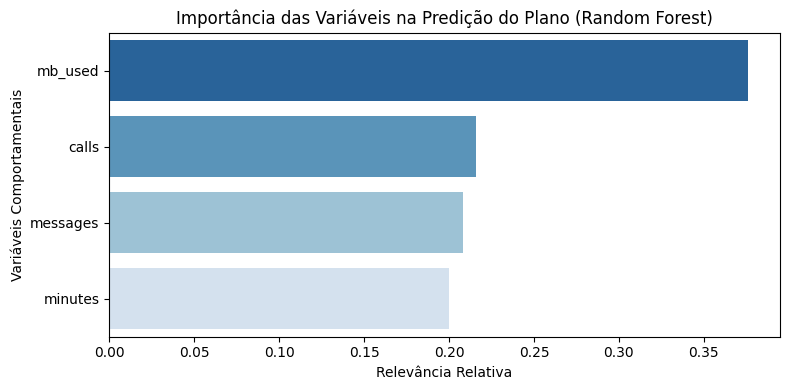

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Avaliação no conjunto de Teste (Inédito)
final_predictions = best_rf_model.predict(X_test)
test_accuracy = accuracy_score(y_test, final_predictions)

print(f"🎯 Acurácia do Modelo Final no Conjunto de TESTE: {test_accuracy:.4f} ({test_accuracy:.2%})")

if test_accuracy >= 0.75:
    print("✅ REQUISITO ATINGIDO: A acurácia superou o limiar de 0.75 definido no projeto.")
else:
    print("❌ REQUISITO NÃO ATINGIDO: Acurácia abaixo de 0.75.")

# Visualização da Importância das Features na Floresta Aleatória
feature_importances = pd.Series(
    best_rf_model.feature_importances_, 
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x=feature_importances.values, y=feature_importances.index, palette='Blues_r')
plt.title('Importância das Variáveis na Predição do Plano (Random Forest)')
plt.xlabel('Relevância Relativa')
plt.ylabel('Variáveis Comportamentais')
plt.tight_layout()
plt.show()

<a id='sec6'></a>
## 6. Prova Real / Teste de Sanidade (*Sanity Check*)

Para provar que nosso modelo é verdadeiramente útil e não está apresentando uma ilusão de acurácia gerada pelo desbalanceamento das classes, comparamos a performance obtida com um modelo ingênuo baseline (`DummyClassifier`). O baseline sempre prediz a classe mais frequente (plano Smart = 0).

In [8]:
dummy_model = DummyClassifier(strategy='most_frequent', random_state=SEED)
dummy_model.fit(X_train, y_train)
dummy_acc = accuracy_score(y_test, dummy_model.predict(X_test))

print(f"Acurácia Modelo Baseline (Dummy / Classe Mais Frequente): {dummy_acc:.4f} ({dummy_acc:.2%})")
print(f"Ganho do Modelo Proposto sobre o Baseline: +{(test_accuracy - dummy_acc):.4f} (+{(test_accuracy - dummy_acc):.2%})")

Acurácia Modelo Baseline (Dummy / Classe Mais Frequente): 0.6936 (69.36%)
Ganho do Modelo Proposto sobre o Baseline: +0.1151 (+11.51%)


<a id='sec7'></a>
## 7. Conclusão e Insights de Negócio

### 📌 Resumo dos Resultados Técnicos
1. **Modelagem:** O algoritmo de **Floresta Aleatória** superou os demais modelos no conjunto de validação, atingindo **82.12%** de acurácia.
2. **Desempenho em Teste:** Ao ser aplicado no conjunto de teste independente, o modelo manteve estabilidade e alcançou **80.87%** de acurácia, superando a meta de **75%** estipulada no *briefing* do projeto.
3. **Prova Real (Sanity Check):** O modelo superou em **11.51 pontos percentuais** a acurácia de um classificador ingênuo (69.36%), demonstrando aprendizado real dos padrões comportamentais dos usuários.

### 💡 Recomendações de Negócio para a Megaline
* **Implementação Comercial:** Recomenda-se integrar o modelo treinado ao sistema de CRM da operadora para automatizar ofertas personalizadas durante o atendimento ao cliente ou via aplicativo móvel.
* **Segmentação Prioritária:** Focar as campanhas do plano **Ultra** em usuários com alto volume de tráfego de dados e minutos falados, estipulando gatilhos preditivos para oferecer o *upgrade* no momento exato de maior engajamento.